<a href="https://colab.research.google.com/github/Abish-Devcraft/DSGP-GRP11-SPATIUM/blob/furniture-classifier/notebooks/02_enrichment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 Enrichment
Input: furniture_v1 (MIT crops) from Drive <br>
Output: furniture_v2 (MIT + Open Images + Ceylon Furniture) on Drive

In [2]:
# connect Drive, restore v1 crops and any images downloaded in an earlier session
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, matplotlib.pyplot as plt, json, time, shutil, requests
from pathlib import Path
from PIL import Image

DRIVE = "/content/drive/MyDrive/DSGP"
NEW = Path("/content/new_images")
!unzip -q -o {DRIVE}/furniture_v1.zip -d /content
if Path(f"{DRIVE}/new_images.zip").exists():
    !unzip -q -o {DRIVE}/new_images.zip -d /content

v1 = pd.read_csv(f"{DRIVE}/furniture_v1_manifest.csv")
print(len(v1), "MIT crops loaded")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1396 MIT crops loaded


In [3]:
# how many images each class still needs to reach the targets
CLASSES = ["sofa", "bed", "chair", "wardrobe", "armchair", "dresser", "table", "side_table",
           "coffee_table", "console_table", "tv_stand", "dressing_table", "nightstand", "desk",
           "bookshelf", "storage_cabinet", "stool_ottoman"]
MIN_N, MAX_N, MIN_ROOM, PER_PRODUCT = 150, 300, 30, 3

cnt = v1["cls"].value_counts()
gap = pd.DataFrame({"mit": [cnt.get(c, 0) for c in CLASSES]}, index=CLASSES)
gap["need_total"] = (MAX_N - gap["mit"]).clip(lower=0)
gap["need_room"] = (MIN_ROOM - gap["mit"]).clip(lower=0)
gap.sort_values("mit")

,mit,need_total,need_room
tv_stand,0,300,30
dressing_table,0,300,30
console_table,0,300,30
desk,11,289,19
coffee_table,18,282,12
storage_cabinet,31,269,0
stool_ottoman,35,265,0
nightstand,48,252,0
side_table,50,250,0
dresser,51,249,0


In [4]:
# download real room photos for weak classes and crop each labelled object
!pip install -q fiftyone
import fiftyone.zoo as foz

OI_MAP = {"Nightstand": "nightstand", "Desk": "desk", "Bookcase": "bookshelf",
          "Coffee table": "coffee_table", "Stool": "stool_ottoman", "Cupboard": "storage_cabinet",
          "Chest of drawers": "dresser", "Wardrobe": "wardrobe"}
MIN_SIDE = 48

rows = []
for oi_name, cls in OI_MAP.items():
    target = int(min(gap.loc[cls, "need_total"], 150))
    if target == 0:
        continue
    ds = foz.load_zoo_dataset("open-images-v7", split="train", label_types=["detections"],
                              classes=[oi_name], max_samples=target * 2, only_matching=True,
                              shuffle=True, seed=42, dataset_name=f"oi_{cls}",
                              drop_existing_dataset=True)
    out = NEW / cls
    out.mkdir(parents=True, exist_ok=True)
    n = 0
    for s in ds:
        if n >= target:
            break
        im = Image.open(s.filepath).convert("RGB")
        W, H = im.size
        for k, d in enumerate(s.ground_truth.detections):
            if d.label != oi_name or getattr(d, "IsGroupOf", False) or getattr(d, "IsDepiction", False):
                continue
            x, y, w, h = d.bounding_box
            box = (int(x * W), int(y * H), int((x + w) * W), int((y + h) * H))
            if min(box[2] - box[0], box[3] - box[1]) < MIN_SIDE:
                continue
            p = out / f"oi_{s.id}_{k}.jpg"
            im.crop(box).save(p)
            rows.append({"path": str(p), "cls": cls, "source": "open_images_v7", "group_id": f"oi_{s.id}",
                         "room_crop": True, "width": box[2] - box[0], "height": box[3] - box[1]})
            n += 1
            if n >= target:
                break
    print(f"{cls:16} {n} crops")

oi_df = pd.DataFrame(rows)
oi_df.to_csv(f"{DRIVE}/oi_manifest.csv", index=False)
!cd /content && zip -q -r {DRIVE}/new_images.zip new_images

INFO:fiftyone.zoo.datasets:Downloading split 'train' to '/root/fiftyone/open-images-v7/train' if necessary


Necessary images already downloaded


INFO:fiftyone.utils.openimages:Necessary images already downloaded


Existing download of split 'train' is sufficient


INFO:fiftyone.zoo.datasets:Existing download of split 'train' is sufficient


Deleting existing dataset 'oi_nightstand'


... (103 outputs left out)

INFO:eta.core.utils: 100% |█████████████████| 208/208 [388.3ms elapsed, 0s remaining, 535.7 samples/s]     


Dataset 'oi_wardrobe' created


INFO:fiftyone.zoo.datasets:Dataset 'oi_wardrobe' created


wardrobe         150 crops


In [6]:
# download product images from the Ceylon Furniture Shopify feed, only as many as each class needs
BASE = "https://ceylonfurniture.lk"
HEADERS = {"User-Agent": "Mozilla/5.0 (university coursework research)"}
MIN_IMG = 224

# remove Ceylon images that went into the wrong class
for c in ["dresser", "dressing_table", "coffee_table", "side_table"]:
    for f in (NEW / c).glob("cf_*"): f.unlink()

CEYLON = {   # order matters: a product is given to the first class that claims it
    "armchair": ["wing-chairs", "cushion-chairs", "relaxing-chairs"],
    "chair": ["dining-chairs", "chairs"],
    "sofa": ["sofas"], "bed": ["beds"], "wardrobe": ["wardrobes"],
    "dressing_table": ["luxury-dressing-units", "standard-dressers", "dressers"],
    "side_table": ["coffee-side-tables"], "coffee_table": ["coffee-table"],
    "console_table": ["console-tables"], "tv_stand": ["tv-entertainment-units"],
    "storage_cabinet": ["side-cupboards"], "desk": ["study-desks", "office-desks"],
    "bookshelf": ["shelves-racks"], "stool_ottoman": ["stools", "round-stools", "bar-chairs"],
}

def get_products(handle):
    out, page = [], 1
    while True:
        r = requests.get(f"{BASE}/collections/{handle}/products.json",
                         params={"limit": 250, "page": page}, headers=HEADERS, timeout=30)
        r.raise_for_status()
        items = r.json().get("products", [])
        if not items:
            return out
        out += items
        page += 1
        time.sleep(1.5)

have = v1["cls"].value_counts().add(oi_df["cls"].value_counts(), fill_value=0)
cf_rows, seen = [], set()

for cls, handles in CEYLON.items():
    remaining = int(MAX_N - have.get(cls, 0))
    out = NEW / cls
    out.mkdir(parents=True, exist_ok=True)
    n = 0
    for h in handles:
        if n >= remaining:
            break
        for prod in get_products(h):
            if n >= remaining:
                break
            if prod["id"] in seen:
                continue
            seen.add(prod["id"])
            for img in prod["images"][:PER_PRODUCT]:
                if n >= remaining:
                    break
                if min(img.get("width") or 0, img.get("height") or 0) < MIN_IMG:
                    continue
                p = out / f"cf_{prod['id']}_{img['position']}.jpg"
                if not p.exists():
                    url = img["src"] + ("&" if "?" in img["src"] else "?") + "width=800"
                    r = requests.get(url, headers=HEADERS, timeout=30)
                    if r.status_code != 200:
                        continue
                    p.write_bytes(r.content)
                    time.sleep(1)
                cf_rows.append({"path": str(p), "cls": cls, "source": "ceylon_furniture",
                                "group_id": f"cf_{prod['id']}", "room_crop": False,
                                "width": img["width"], "height": img["height"],
                                "product_url": f"{BASE}/products/{prod['handle']}"})
                n += 1
    print(f"{cls:16} {n} images (needed {remaining})")

cf_df = pd.DataFrame(cf_rows)
cf_df.to_csv(f"{DRIVE}/cf_manifest.csv", index=False)
!cd /content && zip -q -r {DRIVE}/new_images.zip new_images

armchair         149 images (needed 193)
chair            29 images (needed 31)
sofa             141 images (needed 141)
bed              0 images (needed -12)
wardrobe         90 images (needed 90)
dressing_table   137 images (needed 300)
side_table       50 images (needed 250)
coffee_table     22 images (needed 132)
console_table    113 images (needed 300)
tv_stand         97 images (needed 300)
storage_cabinet  23 images (needed 119)
desk             18 images (needed 139)
bookshelf        13 images (needed 82)
stool_ottoman    18 images (needed 115)


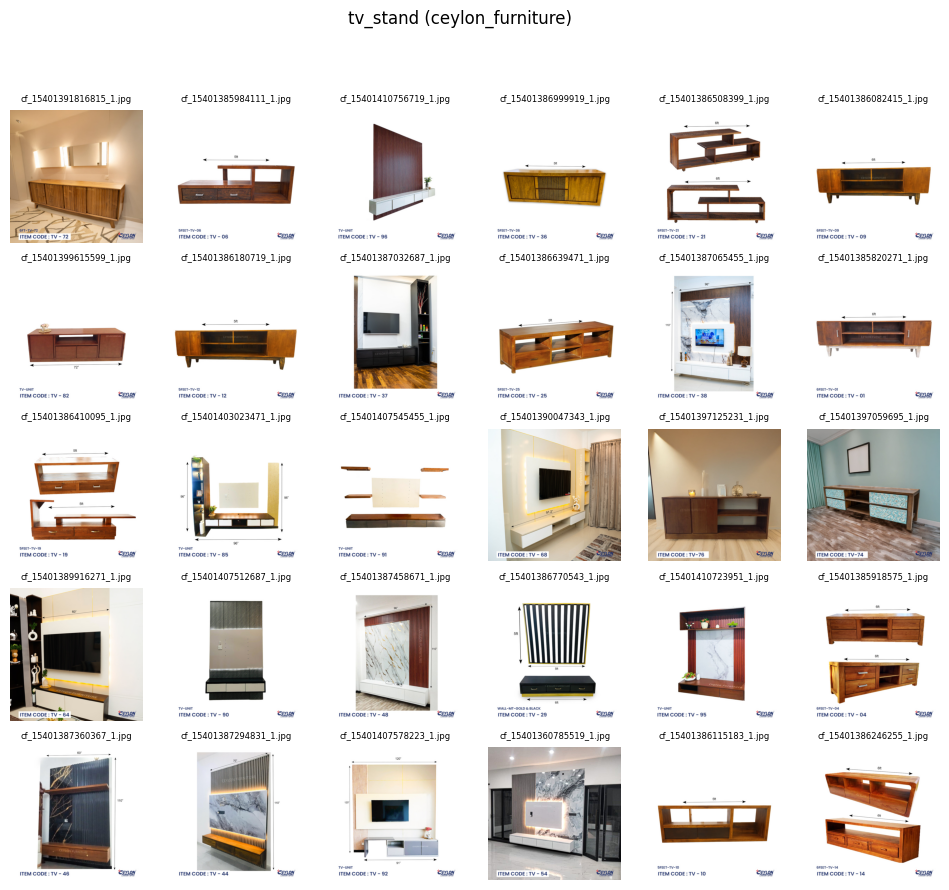

In [7]:
# combine all sources and show a random sample of one class, to spot wrong images
oi_df = pd.read_csv(f"{DRIVE}/oi_manifest.csv")
cf_df = pd.read_csv(f"{DRIVE}/cf_manifest.csv")
allm = pd.concat([v1, oi_df, cf_df], ignore_index=True)

def show(cls, source=None, n=30, seed=0):
    d = allm[allm["cls"] == cls]
    if source:
        d = d[d["source"] == source]
    d = d.sample(min(n, len(d)), random_state=seed)
    fig, axes = plt.subplots(5, 6, figsize=(12, 10))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, p in zip(axes.ravel(), d["path"]):
        ax.imshow(Image.open(p).convert("RGB"))
        ax.set_title(Path(p).name[:24], fontsize=6)
    plt.suptitle(f"{cls} ({source or 'all sources'})")
    plt.show()

show("tv_stand", "ceylon_furniture")   # change the class/source and rerun for each one

In [8]:
# list the filenames of wrong images you saw, then exclude them
BAD = []   # e.g. ["cf_15776677396591_2.jpg", "oi_abc123_0.jpg"]
before = len(allm)
allm = allm[~allm["path"].map(lambda p: Path(p).name).isin(BAD)]
print(f"excluded {before - len(allm)} images")

excluded 0 images


In [9]:
# remove near-identical images, keeping the room-crop copy when there's a tie
!pip install -q imagehash
import imagehash

order = {"mit_indoor": 0, "open_images_v7": 1, "ceylon_furniture": 2}
allm = allm.sort_values("source", key=lambda s: s.map(order)).reset_index(drop=True)
hashes = allm["path"].map(lambda p: str(imagehash.phash(Image.open(p))))
dup = hashes.duplicated()
print("duplicates removed:", int(dup.sum()))
allm = allm[~dup.values].reset_index(drop=True)

duplicates removed: 32


In [10]:
# keep at most 300 per class (room crops first), copy into furniture_v2 and back up to Drive
allm["prio"] = (~allm["room_crop"].astype(bool)).astype(int)
final = (allm.sample(frac=1, random_state=42)
             .sort_values("prio", kind="stable")
             .groupby("cls").head(MAX_N))

V2 = Path("/content/furniture_v2")
shutil.rmtree(V2, ignore_errors=True)
new_paths = []
for r in final.itertuples():
    d = V2 / r.cls
    d.mkdir(parents=True, exist_ok=True)
    dst = d / Path(r.path).name
    shutil.copy(r.path, dst)
    new_paths.append(str(dst))
final = final.assign(path=new_paths).drop(columns="prio")

final.to_csv(f"{DRIVE}/furniture_v2_manifest.csv", index=False)
json.dump(OI_MAP, open(f"{DRIVE}/oi_map.json", "w"), indent=2)
json.dump(CEYLON, open(f"{DRIVE}/ceylon_map.json", "w"), indent=2)
!cd /content && zip -q -r {DRIVE}/furniture_v2.zip furniture_v2

final.groupby(["cls", "source"]).size().unstack(fill_value=0)

source,ceylon_furniture,mit_indoor,open_images_v7
cls,,,
armchair,148,105,0
bed,0,300,0
bookshelf,13,67,149
chair,29,257,0
coffee_table,22,18,150
console_table,113,0,0
desk,18,11,150
dresser,0,51,149
dressing_table,137,0,0
